# **Exercício 01 — Diagnóstico de Câncer e Otimização de Recall**

**Objetivo:** construir e avaliar modelos de Machine Learning para classificar tumores de mama em **Maligno (1)** ou **Benigno (0)**, usando os mesmos três modelos da atividade de referência (SGD, Dummy e Random Forest) e avaliando acurácia, precisão, recall e F1-score.

# **1. Observar o Panorama Geral**

Configuração inicial do setup para o notebook.

In [1]:
# Definição de fontes padrão para os gráficos
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

**Dataset:** Breast Cancer Wisconsin (Diagnostic), disponível no Scikit-Learn por `load_breast_cancer()`. Cada amostra descreve, com 30 atributos numéricos, características dos núcleos celulares observados na imagem digitalizada de uma punção aspirativa por agulha fina (PAAF) de um nódulo de mama.

**Objetivo:** classificar cada tumor como **Maligno (1)** ou **Benigno (0)**, priorizando a detecção dos casos malignos.

**Tipo de Aprendizado:** Aprendizado Supervisionado (cada amostra tem o diagnóstico conhecido)

**Tipo de Tarefa:** Classificação Binária

**Quantidade de entradas e saídas:** MISO (30 atributos de entrada → 1 saída binária)

**Formato de aprendizado:** Aprendizado em lote (o modelo é treinado com todo o conjunto de treino de uma vez)

**Medida de Desempenho:** Acurácia, Precisão, **Recall** (métrica prioritária) e F1-Score, com apoio da Matriz de Confusão. Em triagem de câncer, um **falso negativo** (tumor maligno classificado como benigno) é o erro mais grave, por isso o recall da classe Maligno é o foco do exercício.

# **2. Obtenção dos Dados**

In [2]:
# Importar o dataset Breast Cancer (já vem embutido no Scikit-Learn, sem download)
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

cancer.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [3]:
# os dados de entrada e saída são representados por esses atributos
X, y_original = cancer.data, cancer.target

# X: uma linha por tumor, uma coluna por atributo
print(type(X))
print(X.shape)

# y_original: diagnóstico de cada tumor, na codificação ORIGINAL do dataset (conferida na Etapa 2)
print(y_original.shape)

<class 'numpy.ndarray'>
(569, 30)
(569,)


In [4]:
# Imprime o nome de todas as 30 entradas (características)
for i, nome in enumerate(cancer.feature_names):
    print(f"Entrada {i:2d}: {nome}")

Entrada  0: mean radius
Entrada  1: mean texture
Entrada  2: mean perimeter
Entrada  3: mean area
Entrada  4: mean smoothness
Entrada  5: mean compactness
Entrada  6: mean concavity
Entrada  7: mean concave points
Entrada  8: mean symmetry
Entrada  9: mean fractal dimension
Entrada 10: radius error
Entrada 11: texture error
Entrada 12: perimeter error
Entrada 13: area error
Entrada 14: smoothness error
Entrada 15: compactness error
Entrada 16: concavity error
Entrada 17: concave points error
Entrada 18: symmetry error
Entrada 19: fractal dimension error
Entrada 20: worst radius
Entrada 21: worst texture
Entrada 22: worst perimeter
Entrada 23: worst area
Entrada 24: worst smoothness
Entrada 25: worst compactness
Entrada 26: worst concavity
Entrada 27: worst concave points
Entrada 28: worst symmetry
Entrada 29: worst fractal dimension


## **2.1. Definição do Alvo**

O exercício exige **Maligno = 1** e **Benigno = 0**. Antes de usar o alvo, é preciso conferir como o dataset codifica as classes: `target_names` informa o nome da classe de cada código.

In [5]:
import numpy as np

# Nome de cada código na codificação ORIGINAL (posição 0 -> código 0, posição 1 -> código 1)
print(cancer.target_names)

# Quantidade de amostras de cada código original
for codigo, quantidade in enumerate(np.bincount(y_original)):
    print(f"Código {codigo} ({cancer.target_names[codigo]}): {quantidade} amostras")

['malignant' 'benign']
Código 0 (malignant): 212 amostras
Código 1 (benign): 357 amostras


No dataset original, **0 = maligno** e **1 = benigno**, o inverso do que o exercício pede. Como a classe positiva das métricas (precisão, recall, F1) é a classe 1, é preciso inverter o alvo para que "positivo" signifique **tumor maligno**.

In [6]:
import pandas as pd

# Inverte a codificação: 0 (maligno) -> 1 e 1 (benigno) -> 0
y = 1 - y_original

# Tabela de conferência: cada combinação (original, novo) e sua quantidade
conferencia = pd.DataFrame({
    'Classe': cancer.target_names[y_original],
    'Código original': y_original,
    'Código novo (y)': y
})
conferencia.value_counts().to_frame('Quantidade')

,,,Quantidade
Classe,Código original,Código novo (y),
benign,1,0,357
malignant,0,1,212


## **2.2. Descrição dos Dados**

In [7]:
# Converte X para DataFrame, com o nome de cada atributo nas colunas
df = pd.DataFrame(X, columns=cancer.feature_names)

# Checagem de dados nulos
print(f"Quantidade de dados nulos (NaN) em X: {df.isnull().sum().sum()}")
print(f"Quantidade de dados nulos (NaN) em y: {pd.Series(y).isnull().sum()}")

Quantidade de dados nulos (NaN) em X: 0
Quantidade de dados nulos (NaN) em y: 0


In [8]:
# Estatísticas descritivas dos 10 atributos de média (mean ...)
df.iloc[:, :10].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [9]:
# Rótulos legíveis para as classes, já na codificação do exercício
nomes_classes = {0: 'Benigno (0)', 1: 'Maligno (1)'}

serie_y = pd.Series(y).map(nomes_classes)

# Mostra quantidade absoluta e relativa lado a lado
distribuicao = pd.DataFrame({
    'Quantidade': serie_y.value_counts(),
    'Porcentagem': serie_y.value_counts(normalize=True).map('{:.2%}'.format)
})
print("Distribuição Detalhada das Classes:")
print(distribuicao)

Distribuição Detalhada das Classes:
             Quantidade Porcentagem
Benigno (0)         357      62.74%
Maligno (1)         212      37.26%


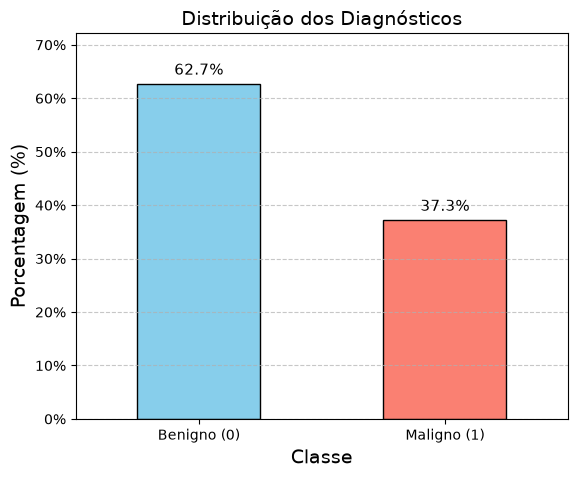

In [10]:
import matplotlib.ticker as mtick

# 1. Calcula as frequências relativas
proporcoes = serie_y.value_counts(normalize=True).sort_index()

plt.figure(figsize=(6, 5))
ax = proporcoes.plot(kind='bar', color=['skyblue', 'salmon'], edgecolor='black')

# 2. Formata o eixo Y para mostrar %
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# 3. Adiciona o valor em porcentagem no topo de cada barra
for i, valor in enumerate(proporcoes):
    ax.text(i, valor + 0.01, f"{valor:.1%}", ha='center', va='bottom', fontsize=11)

plt.title("Distribuição dos Diagnósticos")
plt.xlabel("Classe")
plt.ylabel("Porcentagem (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(proporcoes) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Escala dos atributos:** os atributos têm ordens de grandeza muito diferentes. Os histogramas abaixo comparam dois deles, separados por classe.

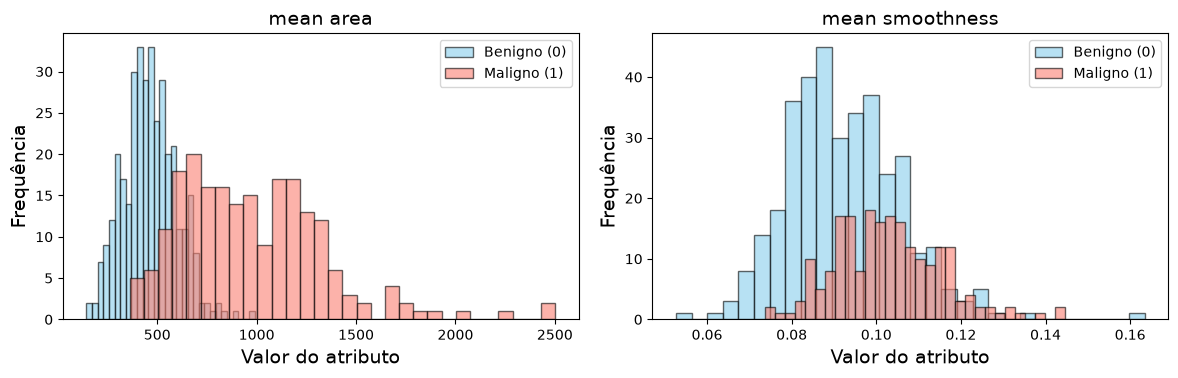

In [11]:
# Dois atributos com escalas bem diferentes
atributos = ['mean area', 'mean smoothness']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, atributo in zip(axes, atributos):
    ax.hist(df.loc[y == 0, atributo], bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Benigno (0)')
    ax.hist(df.loc[y == 1, atributo], bins=30, alpha=0.6, color='salmon', edgecolor='black', label='Maligno (1)')
    ax.set_title(atributo)
    ax.set_xlabel("Valor do atributo")
    ax.set_ylabel("Frequência")
    ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

**Observações:**

* O alvo agora segue a codificação do exercício: **212 Malignos (1)** e **357 Benignos (0)**. As classes são moderadamente desbalanceadas (37,26% de malignos), por isso a acurácia sozinha não basta e a divisão treino/teste deve ser **estratificada**.
* Não há dados nulos.
* `mean area` varia de cerca de 143 a 2501, enquanto `mean smoothness` fica entre 0,05 e 0,16. Essa diferença de escala justifica **padronizar** os dados para o SGD (modelo linear treinado por gradiente); a Random Forest não depende da escala.
* Em `mean area`, os tumores malignos tendem a valores maiores, mas há sobreposição entre as classes; em `mean smoothness`, a sobreposição é maior. Nenhum atributo isolado separa perfeitamente as classes.

## **2.3. Separação dos Dados de Treino e Teste**

O conjunto de **teste** (20%) é separado agora e fica **reservado para a avaliação final**: não será usado para escolher modelos, parâmetros ou limiares. A divisão é **estratificada** (`stratify=y`), para que treino e teste mantenham a mesma proporção de tumores malignos do conjunto completo.

In [12]:
from sklearn.model_selection import train_test_split

# Divisão COM Estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Formato do conjunto de treino: {X_train.shape}")
print(f"Formato do conjunto de teste:  {X_test.shape}")

Formato do conjunto de treino: (455, 30)
Formato do conjunto de teste:  (114, 30)


In [13]:
# Quantidade e proporção de cada classe no conjunto completo, no treino e no teste
comparacao_split = pd.DataFrame({
    'Completo': pd.Series(y).map(nomes_classes).value_counts(),
    'Treino': pd.Series(y_train).map(nomes_classes).value_counts(),
    'Teste': pd.Series(y_test).map(nomes_classes).value_counts()
})

print("Quantidade de amostras por classe:")
print(comparacao_split)

print()
print("Proporção de cada classe:")
print((comparacao_split / comparacao_split.sum()).map('{:.2%}'.format))

Quantidade de amostras por classe:
             Completo  Treino  Teste
Benigno (0)       357     285     72
Maligno (1)       212     170     42

Proporção de cada classe:
            Completo  Treino   Teste
Benigno (0)   62.74%  62.64%  63.16%
Maligno (1)   37.26%  37.36%  36.84%


**Observações:**

* Treino com **455** amostras (170 malignas) e teste com **114** amostras (42 malignas).
* A estratificação manteve a proporção de malignos praticamente igual nos três conjuntos (37,26% completo, 37,36% treino, 36,84% teste).
* No teste, cada tumor maligno não detectado reduz o recall em cerca de 2,4 pontos percentuais (1/42). Com um teste pequeno, poucas amostras mudam bastante as métricas.

# **3. Treinamento dos Modelos de Classificação Binária**

Os três modelos da atividade de referência são treinados **somente com o conjunto de treino** (`X_train`, `y_train`).

Dois deles usam `class_weight='balanced'`, que dá peso maior aos erros da classe minoritária (Maligno) durante o treino. Os pesos são calculados como:

\begin{equation}
  peso_{classe} = \frac{n_{amostras}}{n_{classes} \times n_{amostras\ da\ classe}}
\end{equation}

In [14]:
from sklearn.utils.class_weight import compute_class_weight

# Pesos que class_weight='balanced' atribui a cada classe no conjunto de treino
pesos = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)

for classe, peso in zip([0, 1], pesos):
    print(f"{nomes_classes[classe]}: peso {peso:.3f}")

Benigno (0): peso 0.798
Maligno (1): peso 1.338


##  **3.1 Modelo Gradiente Descendente Estocástico (*Stochastic Gradient Descent*)**

O `SGDClassifier` é um **classificador linear**: para cada tumor, calcula uma pontuação (*score*) como uma soma ponderada dos 30 atributos. Se a pontuação for maior que o limiar (0, por padrão), o tumor é classificado como **Maligno (1)**; caso contrário, como **Benigno (0)**. Os pesos são ajustados pelo algoritmo de Gradiente Descendente Estocástico.

Como depende do gradiente, o modelo é **sensível à escala dos atributos**, e a Etapa 2 mostrou escalas muito diferentes (ex.: `mean area` até 2501, `mean smoothness` abaixo de 0,17). Por isso, os dados são **padronizados** com o `StandardScaler`.

**Adaptação em relação à referência:** o `StandardScaler` e o `SGDClassifier` são combinados em um **`Pipeline`**. Assim, a média e o desvio padrão são sempre calculados apenas com os dados usados no treino. Na validação cruzada (Etapa 5), isso significa recalcular a padronização em cada dobra, sem vazamento de informação da dobra de validação.

In [15]:
#  Classificador Binário Descida de Gradiente Estocástico, com padronização no Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

sgd_clf = make_pipeline(
    StandardScaler(),
    SGDClassifier(class_weight='balanced', random_state=42)
)
sgd_clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('sgdclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


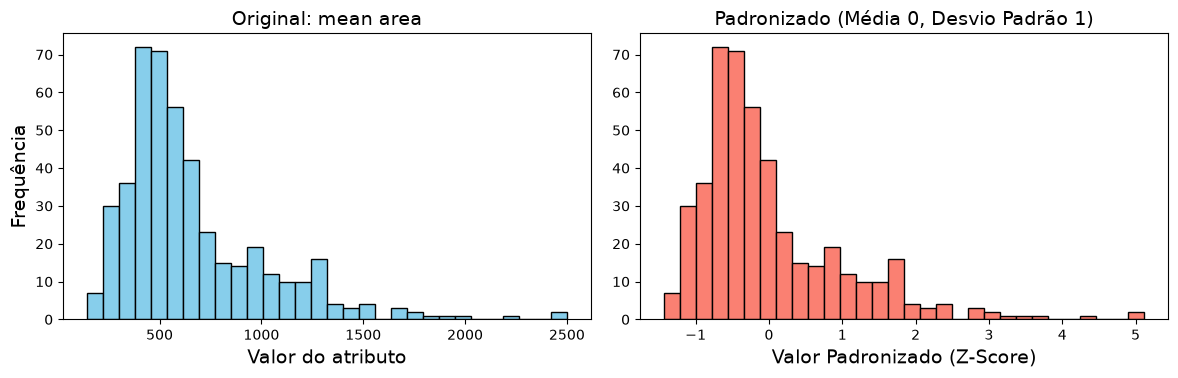

Média aprendida no treino: 659.578
Desvio padrão aprendido no treino: 360.022


In [16]:
# Efeito da padronização aprendida no treino (primeira etapa do Pipeline) em um atributo
scaler = sgd_clf.named_steps['standardscaler']
X_train_scaled = scaler.transform(X_train)

atributo_idx = list(cancer.feature_names).index('mean area')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico dos dados Originais
axes[0].hist(X_train[:, atributo_idx], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title("Original: mean area")
axes[0].set_xlabel("Valor do atributo")
axes[0].set_ylabel("Frequência")

# Gráfico dos dados Padronizados
axes[1].hist(X_train_scaled[:, atributo_idx], bins=30, color='salmon', edgecolor='black')
axes[1].set_title("Padronizado (Média 0, Desvio Padrão 1)")
axes[1].set_xlabel("Valor Padronizado (Z-Score)")

plt.tight_layout()
plt.show()

print(f"Média aprendida no treino: {scaler.mean_[atributo_idx]:.3f}")
print(f"Desvio padrão aprendido no treino: {scaler.scale_[atributo_idx]:.3f}")

In [17]:
# Previsão para um tumor do treino (o Pipeline padroniza automaticamente antes de prever)
# Exemplo: o primeiro tumor MALIGNO do treino, para mostrar a diferença entre os modelos
indice = np.where(y_train == 1)[0][0]
print(f"Índice do exemplo no treino: {indice}")

print(f"Classe real:  {nomes_classes[y_train[indice]]}")
print(f"Classe prevista (SGD): {nomes_classes[sgd_clf.predict(X_train[[indice]])[0]]}")

Índice do exemplo no treino: 0
Classe real:  Maligno (1)
Classe prevista (SGD): Maligno (1)


##  **3.2 Modelo Classificador Bobo (*Dummy Classifier*)**

O `DummyClassifier` serve como **linha de base** (*baseline*). Com `strategy="most_frequent"`, ele memoriza a classe majoritária do treino e a prevê para **qualquer** tumor, sem olhar os atributos.

Aqui, a classe majoritária é **Benigno (0)**. Logo, o Dummy nunca detecta um tumor maligno. Qualquer modelo real deve **superá-lo por uma margem expressiva**, principalmente em recall.

In [18]:
# Classificador que sempre prevê a classe majoritária
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf.fit(X_train, y_train) # não é necessário padronizar

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.63,0.37]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,30
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [19]:
print(f"Classe real:  {nomes_classes[y_train[indice]]}")
print(f"Classe prevista (Dummy): {nomes_classes[dummy_clf.predict(X_train[[indice]])[0]]}")

Classe real:  Maligno (1)
Classe prevista (Dummy): Benigno (0)


##  **3.3 Modelo Floresta Aleatória**

A Floresta Aleatória (*Random Forest*) treina muitas **árvores de decisão**, cada uma com uma amostra diferente dos dados e dos atributos, e combina seus votos. A combinação reduz o *overfitting* de uma árvore isolada.

Como cada divisão de uma árvore compara **um atributo de cada vez** com um limiar, a escala dos atributos não interfere: a Random Forest **não precisa de padronização** e recebe `X_train` diretamente.

In [20]:
# Classificador por floresta aleatória
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(class_weight='balanced', random_state=42)
forest_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [21]:
print(f"Classe real:  {nomes_classes[y_train[indice]]}")
print(f"Classe prevista (Random Forest): {nomes_classes[forest_clf.predict(X_train[[indice]])[0]]}")

Classe real:  Maligno (1)
Classe prevista (Random Forest): Maligno (1)


**Observações:**

* Os três modelos foram treinados apenas com `X_train` e `y_train`; o conjunto de teste continua reservado.
* `class_weight='balanced'` atribuiu peso **1,338** à classe Maligno e **0,798** à classe Benigno: um erro em um tumor maligno pesa cerca de 1,7 vez mais no treino.
* O `StandardScaler` do Pipeline aprendeu, só no treino, média 659,578 e desvio padrão 360,022 para `mean area`; após a padronização, a forma da distribuição é a mesma, mas a escala passa a ser em desvios padrão.
* No exemplo (um tumor **maligno** do treino), SGD e Random Forest previram Maligno, e o Dummy previu Benigno, como esperado de um modelo que sempre responde a classe majoritária. É **um único exemplo já visto no treino**: não mede desempenho. A avaliação começa na próxima seção, com validação cruzada.

# **4. Avaliação de Performance**

Para avaliar um classificador binário, cada previsão é comparada com a classe real. No contexto deste exercício (classe positiva = **Maligno**):

| Sigla | Nome | Significado aqui |
|---|---|---|
| **TP** | Verdadeiro Positivo | Tumor maligno previsto como maligno |
| **TN** | Verdadeiro Negativo | Tumor benigno previsto como benigno |
| **FP** | Falso Positivo | Tumor benigno previsto como maligno (gera exames adicionais desnecessários) |
| **FN** | Falso Negativo | Tumor maligno previsto como benigno (**o erro mais grave**: o câncer não é detectado) |

As medidas de desempenho mais básicas são: Acurácia, Precisão, Recall e F1-Score.

**Acurácia**

A **acurácia** indica a proporção de previsões corretas (positivas e negativas) em relação ao total de casos avaliados.

\begin{equation}
  Acc = \frac{TP + TN}{TP + TN + FP + FN}
\end{equation}

É enganosa em dados desbalanceados: aqui, um modelo que diz "benigno" para todos os tumores acertaria cerca de 63% dos casos (a proporção de benignos) sem detectar nenhum câncer.

**Precisão**

A **precisão** responde: "De todos os tumores que o modelo classificou como malignos, quantos eram realmente malignos?"

\begin{equation}
  Precision = \frac{TP}{TP + FP}
\end{equation}

Precisão baixa significa muitos **falsos positivos**: pacientes com tumor benigno encaminhados para exames adicionais.

**Recall**

O **recall** (sensibilidade) responde: "De todos os tumores realmente malignos, quantos o modelo conseguiu detectar?"

\begin{equation}
  Recall = \frac{TP}{TP + FN}
\end{equation}

É a **métrica prioritária neste exercício**, porque cada **falso negativo** é um câncer não detectado. Em triagem, é preferível um alarme falso (que será descartado por exames complementares) a mandar para casa um paciente com tumor maligno.

**F1-Score**

O **F1-score** combina precisão e recall pela média harmônica, que dá peso maior ao menor dos dois valores.

\begin{equation}
  F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall} = \frac{2TP}{2TP + FP + FN}
\end{equation}

O F1 só é alto quando precisão **e** recall são altos ao mesmo tempo.

## **4.1 Validação Cruzada**

O desempenho é estimado **somente com o conjunto de treino**, por validação cruzada: o treino é dividido em 5 partes (dobras); em cada rodada, o modelo é treinado em 4 dobras e avaliado na dobra restante, que ele não viu. O resultado é a média das 5 rodadas.

**Adaptações em relação à referência:**

* `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`: com apenas 455 amostras de treino, 5 dobras (em vez de 3) dão estimativas mais estáveis; a estratificação mantém a proporção de malignos em cada dobra; e o mesmo objeto `cv` será reutilizado em todas as avaliações, para que todos os modelos sejam comparados **nas mesmas divisões**.
* O SGD está em um `Pipeline`, então a padronização é reajustada no treino de cada dobra (sem vazamento).
* Precisão e F1 usam `zero_division=0`: o Dummy nunca prevê a classe Maligno, e sem esse parâmetro a precisão (0/0) geraria avisos `UndefinedMetricWarning`. O valor 0 é o mesmo que a referência obteve com os avisos.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

# Validação cruzada estratificada, reutilizada em todas as avaliações no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Métricas desejadas (precisão e F1 valem 0 quando não há previsões positivas)
metricas = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': make_scorer(f1_score, zero_division=0)
}

# Nome de cada métrica para exibição
nomes_metricas = {'accuracy': 'Acurácia', 'precision': 'Precisão', 'recall': 'Recall', 'f1': 'F1-Score'}

**SGDClassifier**

In [23]:
# Executa a validação cruzada calculando todas as métricas juntas
resultados_sgd = cross_validate(sgd_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_sgd['test_' + chave].mean():.2%} ± {resultados_sgd['test_' + chave].std():.2%}")

Acurácia  96.92% ± 0.82%
Precisão  96.08% ± 3.35%
Recall    95.88% ± 3.00%
F1-Score  95.89% ± 1.06%


**DummyClassifier**

In [24]:
resultados_dummy = cross_validate(dummy_clf, X_train, y_train, cv=cv, scoring=metricas)

for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_dummy['test_' + chave].mean():.2%} ± {resultados_dummy['test_' + chave].std():.2%}")

Acurácia  62.64% ± 0.00%
Precisão  0.00% ± 0.00%
Recall    0.00% ± 0.00%
F1-Score  0.00% ± 0.00%


**RandomForest**

In [25]:
resultados_forest = cross_validate(forest_clf, X_train, y_train, cv=cv, scoring=metricas)

for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_forest['test_' + chave].mean():.2%} ± {resultados_forest['test_' + chave].std():.2%}")

Acurácia  95.82% ± 1.62%
Precisão  94.18% ± 2.56%
Recall    94.71% ± 2.20%
F1-Score  94.43% ± 2.14%


**Recall em cada dobra**

In [26]:
# Recall de cada modelo em cada uma das 5 dobras (mostra a variação entre as divisões)
recall_por_dobra = pd.DataFrame({
    'Dummy Classifier': resultados_dummy['test_recall'],
    'SGD Classifier': resultados_sgd['test_recall'],
    'Random Forest': resultados_forest['test_recall']
}, index=[f"Dobra {i}" for i in range(1, 6)])

recall_por_dobra.map('{:.2%}'.format)

,Dummy Classifier,SGD Classifier,Random Forest
Dobra 1,0.00%,91.18%,94.12%
Dobra 2,0.00%,97.06%,97.06%
Dobra 3,0.00%,97.06%,91.18%
Dobra 4,0.00%,94.12%,94.12%
Dobra 5,0.00%,100.00%,97.06%


**Gráfico dos Resultados de Validação Cruzada**

In [27]:
# Estrutura de dados com a média de cada métrica para cada modelo
resultados_cv = {
    'Dummy Classifier': resultados_dummy,
    'SGD Classifier': resultados_sgd,
    'Random Forest': resultados_forest
}

df_comparacao = pd.DataFrame({
    modelo: {nome: res['test_' + chave].mean() for chave, nome in nomes_metricas.items()}
    for modelo, res in resultados_cv.items()
}).T
df_comparacao.index.name = 'Modelo'

df_comparacao.map('{:.2%}'.format)

,Acurácia,Precisão,Recall,F1-Score
Modelo,,,,
Dummy Classifier,62.64%,0.00%,0.00%,0.00%
SGD Classifier,96.92%,96.08%,95.88%,95.89%
Random Forest,95.82%,94.18%,94.71%,94.43%


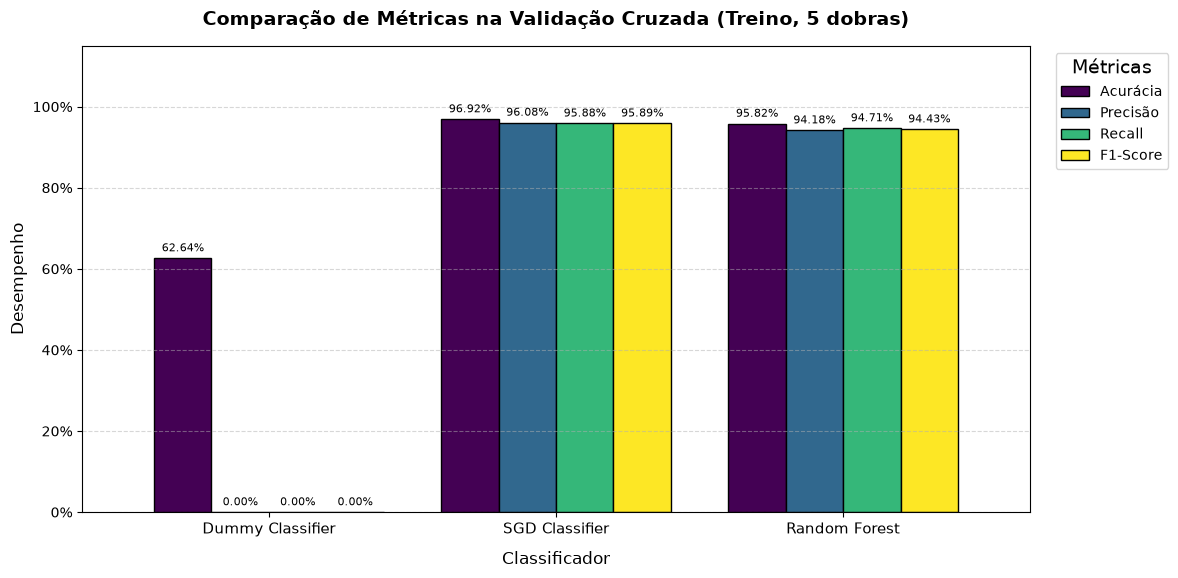

In [28]:
# Configura o tamanho da figura
fig, ax = plt.subplots(figsize=(12, 6))

# Plota o gráfico de barras diretamente do DataFrame
df_comparacao.plot(kind='bar', ax=ax, width=0.8, colormap='viridis', edgecolor='black')

# Estilização do gráfico
plt.title("Comparação de Métricas na Validação Cruzada (Treino, 5 dobras)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classificador", fontsize=12, labelpad=10)
plt.ylabel("Desempenho", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 1.15)

# Formata o eixo Y para mostrar porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

# Adiciona os valores em porcentagem no topo das barras
for container in ax.containers:
    labels = [f"{v * 100:.2f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=0)

plt.tight_layout()
plt.show()

**Observações:**

* **Dummy:** acurácia de 62,64%, exatamente a proporção de benignos no treino, com precisão, recall e F1 iguais a 0. É a armadilha da acurácia: um modelo que nunca detecta câncer parece "acertar" quase dois terços dos casos.
* **SGD e Random Forest** superam o Dummy por ampla margem em todas as métricas. Na média das 5 dobras, o SGD obteve recall de 95,88% e a Random Forest, 94,71%. Somando as dobras, isso corresponde a 7 e 9 tumores malignos não detectados, respectivamente, de 170.
* A diferença entre SGD e Random Forest (cerca de 1 ponto percentual, ou 2 tumores) é **menor que a variação entre as dobras** (desvio padrão de 2 a 3 pontos no recall). Com estes dados, não é possível afirmar que um modelo é claramente superior ao outro.
* Cada dobra de validação tem 34 tumores malignos, então o recall de uma dobra varia em degraus de 1/34 ≈ 2,94 pontos percentuais.
* Estes resultados usam o **limiar padrão** de cada modelo. A próxima etapa analisa como o limiar altera o equilíbrio entre precisão e recall.

 ### ***Trade-off* da Precisão e Recall**

Precisão e recall costumam ser **inversamente relacionados**. Para cada tumor, o modelo calcula uma **pontuação** (*score*) e compara com um **limiar** (*threshold*):

* **SGD:** a pontuação é a `decision_function` (soma ponderada dos atributos); limiar padrão = **0**.
* **Random Forest:** a pontuação é a probabilidade de Maligno (`predict_proba`); limiar padrão = **0,5**.

**Baixar o limiar** faz o modelo classificar mais tumores como malignos: os **falsos negativos diminuem** (recall sobe), mas os **falsos positivos aumentam** (precisão cai). Subir o limiar faz o contrário.

Para estudar o limiar **sem usar o teste**, as pontuações do treino são obtidas com `cross_val_predict`: cada tumor recebe a pontuação de um modelo que **não o viu** no treino (o mesmo `cv` da validação cruzada).

**Pontuações fora da amostra**

In [29]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# SGD: pontuação da função de decisão (limiar padrão = 0)
y_scores_sgd = cross_val_predict(sgd_clf, X_train, y_train, cv=cv,
                                 method="decision_function")

# Random Forest: probabilidade da classe Maligno (limiar padrão = 0,5)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train, cv=cv,
                                    method="predict_proba")
y_scores_forest = y_probas_forest[:, 1]

# Precisão e recall para cada limiar possível
precisions_sgd, recalls_sgd, thresholds_sgd = precision_recall_curve(y_train, y_scores_sgd)
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(y_train, y_scores_forest)

print(f"SGD: pontuações de {y_scores_sgd.min():.2f} a {y_scores_sgd.max():.2f}; {len(thresholds_sgd)} limiares avaliados")
print(f"Random Forest: probabilidades de {y_scores_forest.min():.2f} a {y_scores_forest.max():.2f}; {len(thresholds_forest)} limiares avaliados")

SGD: pontuações de -147.40 a 508.64; 455 limiares avaliados
Random Forest: probabilidades de 0.00 a 1.00; 76 limiares avaliados


**Escolha do limiar: critério F2**

Em vez de impor uma meta arbitrária de recall, o limiar é escolhido pelo maior **F2-score**, uma média harmônica ponderada que dá ao **recall o dobro do peso** da precisão:

\begin{equation}
  F_\beta = (1 + \beta^2) \times \frac{Precision \times Recall}{\beta^2 \times Precision + Recall} \qquad \Rightarrow \qquad F_2 = \frac{5 \times Precision \times Recall}{4 \times Precision + Recall}
\end{equation}

Com β = 1, obtém-se o F1 (pesos iguais). Com β = 2, perder um maligno (FN) pesa mais que um alarme falso (FP), coerente com o objetivo do exercício. A escolha usa **somente** as pontuações fora da amostra do treino.

In [30]:
# F2 para cada limiar (o último ponto da curva, recall = 0, não tem limiar associado)
def f2_por_limiar(precisions, recalls):
    p, r = precisions[:-1], recalls[:-1]
    denominador = 4 * p + r
    return np.divide(5 * p * r, denominador, out=np.zeros_like(denominador), where=denominador > 0)

f2_sgd = f2_por_limiar(precisions_sgd, recalls_sgd)
f2_forest = f2_por_limiar(precisions_forest, recalls_forest)

# Limiar com o maior F2 em cada modelo
idx_sgd = f2_sgd.argmax()
idx_forest = f2_forest.argmax()
limiar_sgd = thresholds_sgd[idx_sgd]
limiar_forest = thresholds_forest[idx_forest]

print(f"SGD: limiar escolhido = {limiar_sgd:.4f} (padrão = 0)")
print(f"Random Forest: limiar escolhido = {limiar_forest:.4f} (padrão = 0,5)")

SGD: limiar escolhido = -2.9289 (padrão = 0)
Random Forest: limiar escolhido = 0.4500 (padrão = 0,5)


**Curva Precisão × Recall**

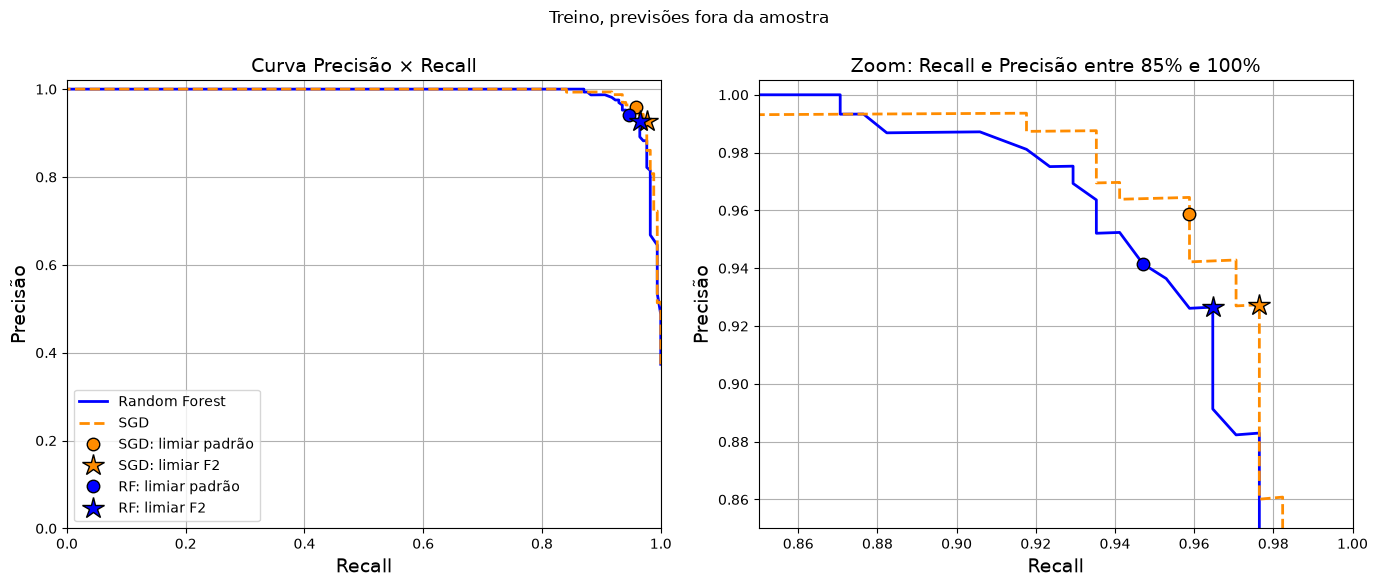

In [31]:
# Índices dos limiares padrão na curva (primeiro limiar acima do padrão)
idx_padrao_sgd = (thresholds_sgd > 0).argmax()
idx_padrao_forest = (thresholds_forest > 0.5).argmax()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mesmo gráfico duas vezes: visão completa (esquerda) e zoom na região de interesse (direita)
for ax, limites, titulo in zip(axes,
                               [[0, 1, 0, 1.02], [0.85, 1.0, 0.85, 1.005]],
                               ["Curva Precisão × Recall", "Zoom: Recall e Precisão entre 85% e 100%"]):
    ax.plot(recalls_forest, precisions_forest, "b-", linewidth=2, label="Random Forest")
    ax.plot(recalls_sgd, precisions_sgd, "--", color="darkorange", linewidth=2, label="SGD")

    # Pontos no limiar padrão (círculo) e no limiar escolhido por F2 (estrela)
    ax.plot(recalls_sgd[idx_padrao_sgd], precisions_sgd[idx_padrao_sgd], "o", color="darkorange", markersize=9, markeredgecolor="k", label="SGD: limiar padrão")
    ax.plot(recalls_sgd[idx_sgd], precisions_sgd[idx_sgd], "*", color="darkorange", markersize=16, markeredgecolor="k", label="SGD: limiar F2")
    ax.plot(recalls_forest[idx_padrao_forest], precisions_forest[idx_padrao_forest], "bo", markersize=9, markeredgecolor="k", label="RF: limiar padrão")
    ax.plot(recalls_forest[idx_forest], precisions_forest[idx_forest], "b*", markersize=16, markeredgecolor="k", label="RF: limiar F2")

    ax.set_title(titulo)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precisão")
    ax.axis(limites)
    ax.grid()

axes[0].legend(loc="lower left", fontsize=10)
plt.suptitle("Treino, previsões fora da amostra", fontsize=12)
plt.tight_layout()
plt.show()

**Precisão e Recall em função do limiar**

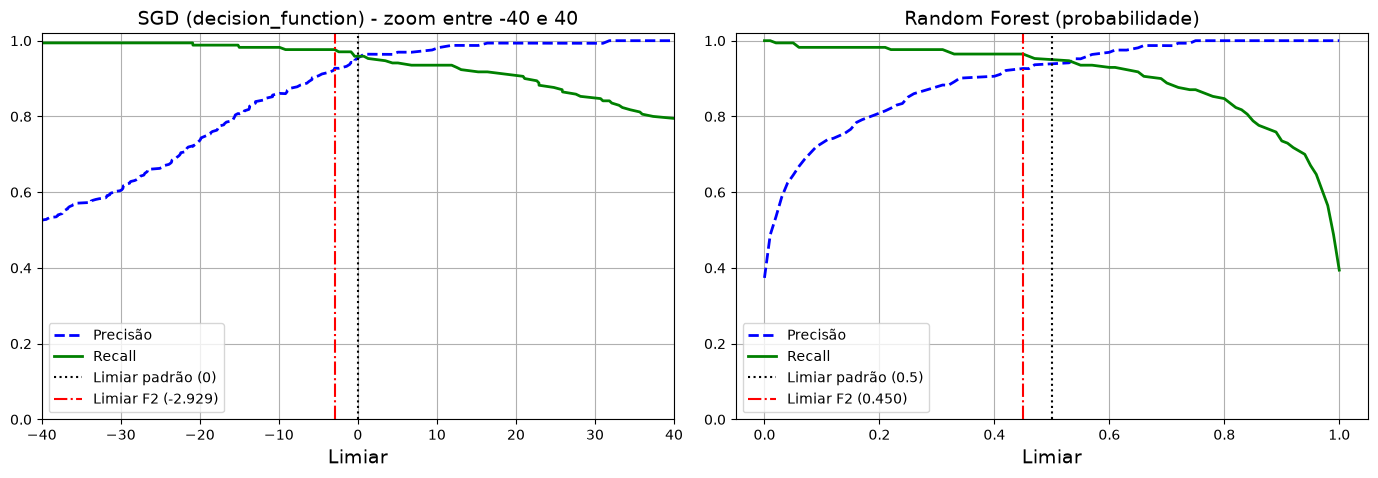

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

curvas = [
    ("SGD (decision_function) - zoom entre -40 e 40", thresholds_sgd, precisions_sgd, recalls_sgd, 0, limiar_sgd),
    ("Random Forest (probabilidade)", thresholds_forest, precisions_forest, recalls_forest, 0.5, limiar_forest),
]

for ax, (titulo, thresholds, precisions, recalls, padrao, escolhido) in zip(axes, curvas):
    ax.plot(thresholds, precisions[:-1], "b--", linewidth=2, label="Precisão")
    ax.plot(thresholds, recalls[:-1], "g-", linewidth=2, label="Recall")
    ax.axvline(padrao, color="k", linestyle=":", label=f"Limiar padrão ({padrao})")
    ax.axvline(escolhido, color="r", linestyle="-.", label=f"Limiar F2 ({escolhido:.3f})")
    ax.set_title(titulo)
    ax.set_xlabel("Limiar")
    ax.set_ylim(0, 1.02)
    ax.grid()
    ax.legend(loc="lower left", fontsize=10)

# As pontuações do SGD vão de cerca de -147 a 509; o zoom mostra a região dos limiares
axes[0].set_xlim(-40, 40)

plt.tight_layout()
plt.show()

**Comparação: limiar padrão × limiar ajustado (treino, fora da amostra)**

In [33]:
from sklearn.metrics import confusion_matrix, recall_score, fbeta_score

# Previsões fora da amostra em cada limiar
# (padrão: o modelo prevê Maligno quando score > 0 no SGD e probabilidade > 0,5 na RF)
previsoes_limiar = {
    'SGD - padrão (0)': y_scores_sgd > 0,
    f'SGD - F2 ({limiar_sgd:.3f})': y_scores_sgd >= limiar_sgd,
    'Random Forest - padrão (0,5)': y_scores_forest > 0.5,
    f'Random Forest - F2 ({limiar_forest:.3f})': y_scores_forest >= limiar_forest,
}

linhas = []
for nome, y_pred in previsoes_limiar.items():
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()
    linhas.append({
        'Modelo - limiar': nome,
        'Precisão': precision_score(y_train, y_pred),
        'Recall': recall_score(y_train, y_pred),
        'F1-Score': f1_score(y_train, y_pred),
        'F2-Score': fbeta_score(y_train, y_pred, beta=2),
        'FN': fn,
        'FP': fp,
    })

df_limiares = pd.DataFrame(linhas).set_index('Modelo - limiar')
# Exibe as métricas em porcentagem, ao lado das contagens de erros
colunas_pct = ['Precisão', 'Recall', 'F1-Score', 'F2-Score']
df_limiares[colunas_pct].map('{:.2%}'.format).join(df_limiares[['FN', 'FP']])

,Precisão,Recall,F1-Score,F2-Score,FN,FP
Modelo - limiar,,,,,,
SGD - padrão (0),95.88%,95.88%,95.88%,95.88%,7,7
SGD - F2 (-2.929),92.74%,97.65%,95.13%,96.62%,4,13
"Random Forest - padrão (0,5)",94.15%,94.71%,94.43%,94.59%,9,10
Random Forest - F2 (0.450),92.66%,96.47%,94.52%,95.68%,6,13


**Observações:**

* No limiar padrão, os números coincidem com a validação cruzada da seção 4.1: SGD com 7 FN e Random Forest com 9 FN, de 170 malignos.
* **SGD:** baixar o limiar de 0 para −2,929 reduziu os falsos negativos de **7 para 4** (recall de 95,88% para 97,65%), ao custo de aumentar os falsos positivos de **7 para 13** (precisão de 95,88% para 92,74%).
* **Random Forest:** baixar o limiar de 0,5 para 0,45 reduziu os falsos negativos de **9 para 6** (recall de 94,71% para 96,47%), com falsos positivos passando de **10 para 13** (precisão de 94,15% para 92,66%).
* Nos dois modelos, **3 cânceres a mais foram detectados** no treino. O custo foi de 6 (SGD) e 3 (RF) alarmes falsos adicionais, ou seja, pacientes com tumor benigno que fariam exames complementares. O F1 praticamente não mudou; o F2, que prioriza o recall, aumentou.
* Os limiares foram escolhidos **apenas com previsões fora da amostra do treino**. O efeito real será verificado no teste, na Etapa 8, sem nenhum novo ajuste.

## **4.2 Matriz de Confusão**

A Matriz de Confusão compara as classes reais com as previstas e mostra **onde** cada modelo acerta e erra:

| | Previsto Benigno (0) | Previsto Maligno (1) |
|---|---|---|
| **Real Benigno (0)** | TN | FP |
| **Real Maligno (1)** | **FN** | TP |

As previsões do treino são obtidas com `cross_val_predict` (o mesmo `cv` da validação cruzada): cada tumor é classificado por um modelo que **não o viu** no treinamento. Para o SGD e a Random Forest, há uma matriz no **limiar padrão** e outra no **limiar ajustado** (F2) da seção anterior.

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

# Desenha uma matriz de confusão com classes, eixos e siglas identificados (usada também no teste)
def plot_matriz_confusao(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred)
    display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                     display_labels=['Benigno (0)', 'Maligno (1)'])
    display.plot(cmap=plt.cm.Blues)

    # Escreve a sigla de cada célula logo acima do valor (mesma cor do número, para manter o contraste)
    siglas = [['TN', 'FP'],
              ['FN', 'TP']]
    for i in range(2):          # i = linha (classe real)
        for j in range(2):      # j = coluna (classe prevista)
            valor = display.text_[i, j]
            valor.set_position((j, i + 0.12))
            display.ax_.text(j, i - 0.18, siglas[i][j], ha='center', va='center',
                             fontsize=13, fontweight='bold', color=valor.get_color())

    plt.title(titulo)
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.show()
    return cm

**DummyClassifier**

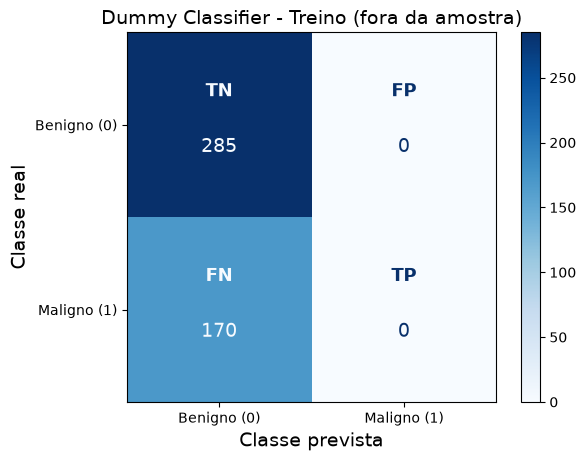

In [35]:
# gera uma previsão para cada dado do conjunto de treino, mas cada previsão é
# feita por um modelo que nunca viu aquele dado específico durante o treinamento.
y_train_pred_dummy = cross_val_predict(dummy_clf, X_train, y_train, cv=cv)

cm_treino_dummy = plot_matriz_confusao(y_train, y_train_pred_dummy,
                                       "Dummy Classifier - Treino (fora da amostra)")

**SGDClassifier — limiar padrão (0)**

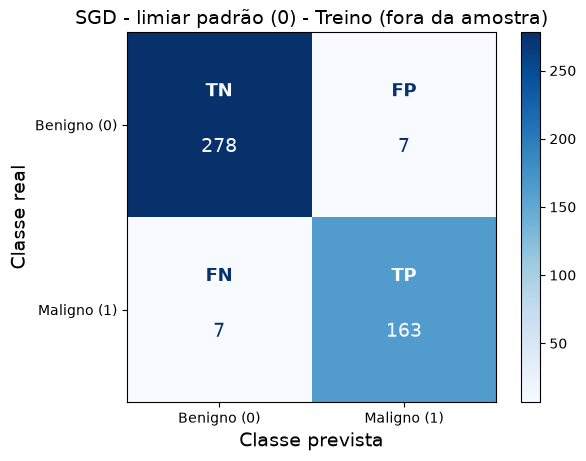

In [36]:
y_train_pred_sgd = cross_val_predict(sgd_clf, X_train, y_train, cv=cv)

cm_treino_sgd = plot_matriz_confusao(y_train, y_train_pred_sgd,
                                     "SGD - limiar padrão (0) - Treino (fora da amostra)")

**SGDClassifier — limiar ajustado (F2)**

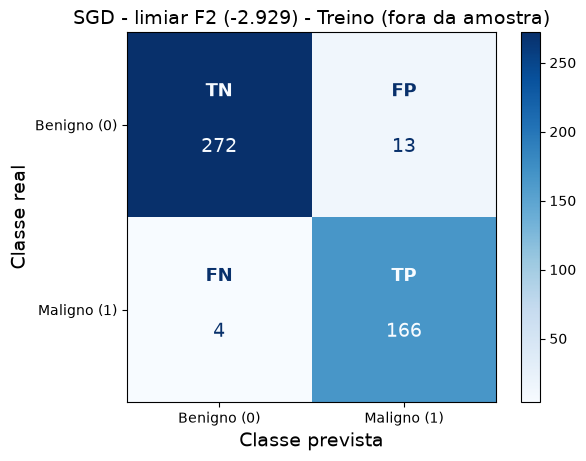

In [37]:
# Aplica o limiar escolhido na seção anterior às pontuações fora da amostra
y_train_pred_sgd_f2 = (y_scores_sgd >= limiar_sgd).astype(int)

cm_treino_sgd_f2 = plot_matriz_confusao(y_train, y_train_pred_sgd_f2,
                                        f"SGD - limiar F2 ({limiar_sgd:.3f}) - Treino (fora da amostra)")

**Random Forest — limiar padrão (0,5)**

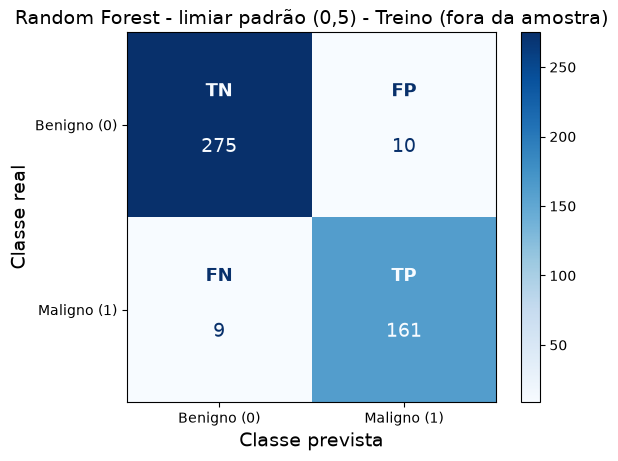

In [38]:
y_train_pred_forest = cross_val_predict(forest_clf, X_train, y_train, cv=cv)

cm_treino_forest = plot_matriz_confusao(y_train, y_train_pred_forest,
                                        "Random Forest - limiar padrão (0,5) - Treino (fora da amostra)")

**Random Forest — limiar ajustado (F2)**

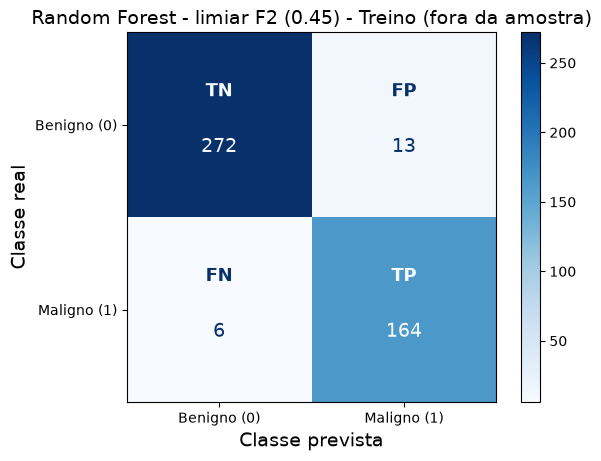

In [39]:
y_train_pred_forest_f2 = (y_scores_forest >= limiar_forest).astype(int)

cm_treino_forest_f2 = plot_matriz_confusao(y_train, y_train_pred_forest_f2,
                                           f"Random Forest - limiar F2 ({limiar_forest:.2f}) - Treino (fora da amostra)")

**Resumo das Matrizes de Confusão no Treino**

In [40]:
# Contagens de cada matriz lado a lado (ravel: TN, FP, FN, TP)
matrizes_treino = {
    'Dummy': cm_treino_dummy,
    'SGD - padrão': cm_treino_sgd,
    'SGD - F2': cm_treino_sgd_f2,
    'Random Forest - padrão': cm_treino_forest,
    'Random Forest - F2': cm_treino_forest_f2,
}

resumo_treino = pd.DataFrame(
    [cm.ravel() for cm in matrizes_treino.values()],
    index=matrizes_treino.keys(),
    columns=['TN', 'FP', 'FN', 'TP']
)
resumo_treino

,TN,FP,FN,TP
Dummy,285,0,170,0
SGD - padrão,278,7,7,163
SGD - F2,272,13,4,166
Random Forest - padrão,275,10,9,161
Random Forest - F2,272,13,6,164


**Observações:**

* **Dummy:** classifica todos os 455 tumores como benignos, com **170 falsos negativos**: nenhum câncer é detectado.
* **SGD:** no limiar padrão, erra 7 malignos (FN) e 7 benignos (FP). Com o limiar F2, os FN caem para **4** e os FP sobem para 13.
* **Random Forest:** no limiar padrão, 9 FN e 10 FP. Com o limiar F2, **6** FN e 13 FP.
* Com os limiares F2, os dois modelos têm o mesmo número de falsos positivos (13); o SGD deixa de detectar 2 malignos a menos que a Random Forest (4 contra 6).
* Todas as previsões são fora da amostra, mas os limiares F2 foram escolhidos com essas mesmas pontuações. Por isso, as matrizes "F2" do treino tendem a ser um pouco otimistas; a verificação independente é o teste.

# **5. Teste**

Avaliação final no **conjunto de teste** (114 tumores, 42 malignos), separado na seção 2.3 e não usado até aqui.

* Os modelos são os treinados na seção 3 com **todo o conjunto de treino**; nada é retreinado.
* Os limiares ajustados (F2) são os escolhidos na seção 4 **somente com o treino**: SGD = `limiar_sgd` e Random Forest = `limiar_forest`.
* Nenhum modelo, parâmetro ou limiar será alterado depois desta avaliação.

In [41]:
from sklearn.metrics import classification_report, accuracy_score

nomes_classes_relatorio = ['Benigno (0)', 'Maligno (1)']

# Calcula e exibe as métricas de uma previsão no teste (usada para cada modelo e limiar)
def metricas_teste(y_pred):
    resultado = {
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'F2-Score': fbeta_score(y_test, y_pred, beta=2, zero_division=0),
    }
    for nome, valor in resultado.items():
        print(f"{nome:9s} {valor:.2%}")
    return resultado

## **5.1. SGDClassifier**

**Limiar padrão (0)**

In [42]:
print("="*40)
print("     TESTE: SGD CLASSIFIER - LIMIAR PADRÃO")
print("="*40)

# Predição (o Pipeline aplica a padronização aprendida no treino)
y_pred_sgd = sgd_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_sgd, target_names=nomes_classes_relatorio))

# Resumo
teste_sgd = metricas_teste(y_pred_sgd)

     TESTE: SGD CLASSIFIER - LIMIAR PADRÃO
              precision    recall  f1-score   support

 Benigno (0)       0.96      0.92      0.94        72
 Maligno (1)       0.87      0.93      0.90        42

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114

Acurácia  92.11%
Precisão  86.67%
Recall    92.86%
F1-Score  89.66%
F2-Score  91.55%


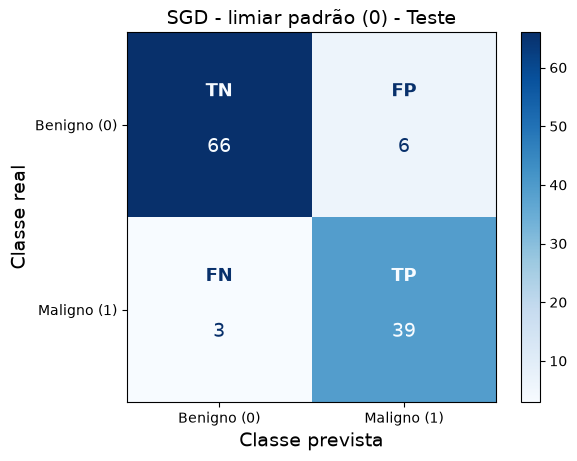

In [43]:
cm_teste_sgd = plot_matriz_confusao(y_test, y_pred_sgd, "SGD - limiar padrão (0) - Teste")

**Limiar ajustado (F2)**

In [44]:
print("="*40)
print(f"     TESTE: SGD CLASSIFIER - LIMIAR F2 ({limiar_sgd:.3f})")
print("="*40)

# Pontuação de cada tumor do teste e aplicação do limiar escolhido no treino
y_scores_teste_sgd = sgd_clf.decision_function(X_test)
y_pred_sgd_f2 = (y_scores_teste_sgd >= limiar_sgd).astype(int)

print(classification_report(y_test, y_pred_sgd_f2, target_names=nomes_classes_relatorio))

teste_sgd_f2 = metricas_teste(y_pred_sgd_f2)

     TESTE: SGD CLASSIFIER - LIMIAR F2 (-2.929)
              precision    recall  f1-score   support

 Benigno (0)       0.97      0.92      0.94        72
 Maligno (1)       0.87      0.95      0.91        42

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

Acurácia  92.98%
Precisão  86.96%
Recall    95.24%
F1-Score  90.91%
F2-Score  93.46%


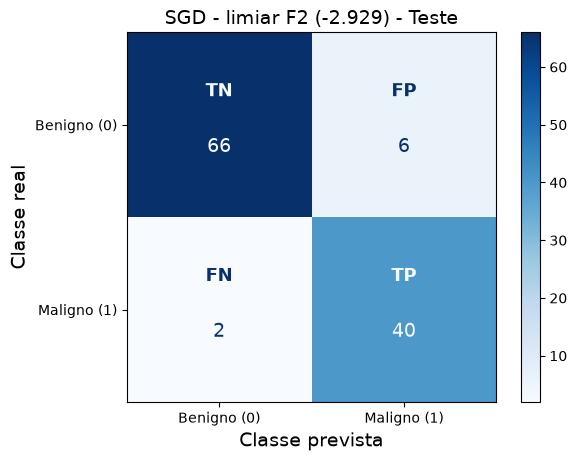

In [45]:
cm_teste_sgd_f2 = plot_matriz_confusao(y_test, y_pred_sgd_f2, f"SGD - limiar F2 ({limiar_sgd:.3f}) - Teste")

## **5.2. DummyClassifier**

In [46]:
print("="*40)
print("     TESTE: DUMMY CLASSIFIER")
print("="*40)

# Predição
y_pred_dummy = dummy_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_dummy, target_names=nomes_classes_relatorio, zero_division=0))

# Resumo
teste_dummy = metricas_teste(y_pred_dummy)

     TESTE: DUMMY CLASSIFIER
              precision    recall  f1-score   support

 Benigno (0)       0.63      1.00      0.77        72
 Maligno (1)       0.00      0.00      0.00        42

    accuracy                           0.63       114
   macro avg       0.32      0.50      0.39       114
weighted avg       0.40      0.63      0.49       114

Acurácia  63.16%
Precisão  0.00%
Recall    0.00%
F1-Score  0.00%
F2-Score  0.00%


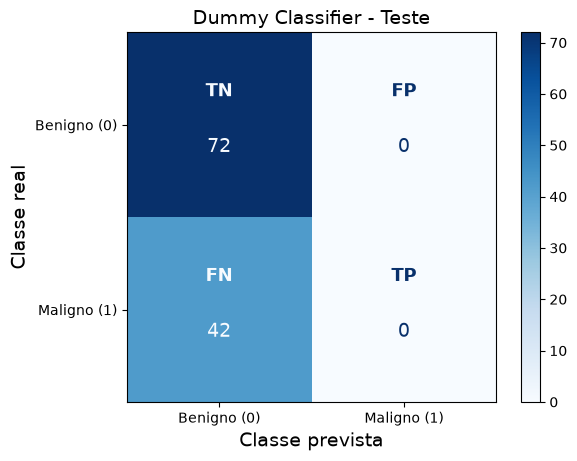

In [47]:
cm_teste_dummy = plot_matriz_confusao(y_test, y_pred_dummy, "Dummy Classifier - Teste")

## **5.3. Random Forest**

**Limiar padrão (0,5)**

In [48]:
print("="*40)
print("     TESTE: RANDOM FOREST - LIMIAR PADRÃO")
print("="*40)

# Predição
y_pred_forest = forest_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_forest, target_names=nomes_classes_relatorio))

# Resumo
teste_forest = metricas_teste(y_pred_forest)

     TESTE: RANDOM FOREST - LIMIAR PADRÃO
              precision    recall  f1-score   support

 Benigno (0)       0.96      1.00      0.98        72
 Maligno (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Acurácia  97.37%
Precisão  100.00%
Recall    92.86%
F1-Score  96.30%
F2-Score  94.20%


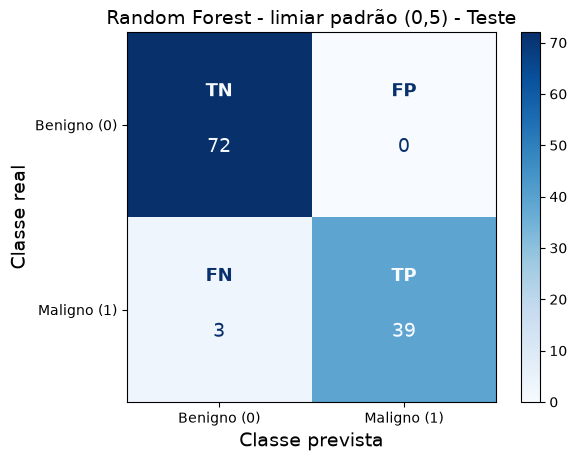

In [49]:
cm_teste_forest = plot_matriz_confusao(y_test, y_pred_forest, "Random Forest - limiar padrão (0,5) - Teste")

**Limiar ajustado (F2)**

In [50]:
print("="*40)
print(f"     TESTE: RANDOM FOREST - LIMIAR F2 ({limiar_forest:.2f})")
print("="*40)

# Probabilidade de Maligno de cada tumor do teste e aplicação do limiar escolhido no treino
y_scores_teste_forest = forest_clf.predict_proba(X_test)[:, 1]
y_pred_forest_f2 = (y_scores_teste_forest >= limiar_forest).astype(int)

print(classification_report(y_test, y_pred_forest_f2, target_names=nomes_classes_relatorio))

teste_forest_f2 = metricas_teste(y_pred_forest_f2)

     TESTE: RANDOM FOREST - LIMIAR F2 (0.45)
              precision    recall  f1-score   support

 Benigno (0)       0.96      0.99      0.97        72
 Maligno (1)       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Acurácia  96.49%
Precisão  97.50%
Recall    92.86%
F1-Score  95.12%
F2-Score  93.75%


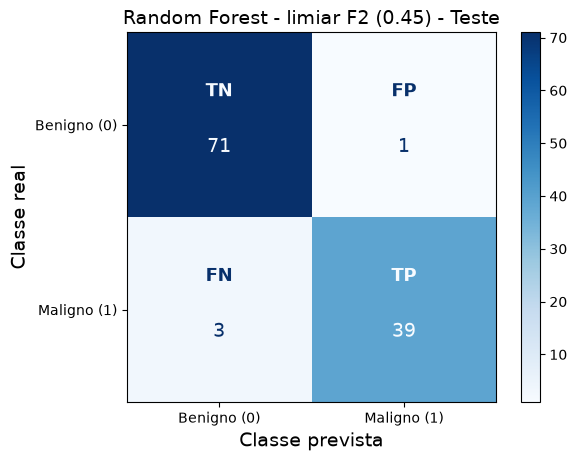

In [51]:
cm_teste_forest_f2 = plot_matriz_confusao(y_test, y_pred_forest_f2, f"Random Forest - limiar F2 ({limiar_forest:.2f}) - Teste")

## **5.4. Resumo do Teste**

In [52]:
# Métricas e contagens de erros de todos os modelos e limiares no teste
resultados_teste = {
    'Dummy Classifier': (teste_dummy, cm_teste_dummy),
    'SGD - padrão': (teste_sgd, cm_teste_sgd),
    'SGD - F2': (teste_sgd_f2, cm_teste_sgd_f2),
    'Random Forest - padrão': (teste_forest, cm_teste_forest),
    'Random Forest - F2': (teste_forest_f2, cm_teste_forest_f2),
}

df_teste = pd.DataFrame({modelo: metricas for modelo, (metricas, cm) in resultados_teste.items()}).T
df_teste[['TN', 'FP', 'FN', 'TP']] = [cm.ravel() for metricas, cm in resultados_teste.values()]
df_teste.index.name = 'Modelo'

colunas_pct = ['Acurácia', 'Precisão', 'Recall', 'F1-Score', 'F2-Score']
df_teste[colunas_pct].map('{:.2%}'.format).join(df_teste[['TN', 'FP', 'FN', 'TP']].astype(int))

,Acurácia,Precisão,Recall,F1-Score,F2-Score,TN,FP,FN,TP
Modelo,,,,,,,,,
Dummy Classifier,63.16%,0.00%,0.00%,0.00%,0.00%,72,0,42,0
SGD - padrão,92.11%,86.67%,92.86%,89.66%,91.55%,66,6,3,39
SGD - F2,92.98%,86.96%,95.24%,90.91%,93.46%,66,6,2,40
Random Forest - padrão,97.37%,100.00%,92.86%,96.30%,94.20%,72,0,3,39
Random Forest - F2,96.49%,97.50%,92.86%,95.12%,93.75%,71,1,3,39


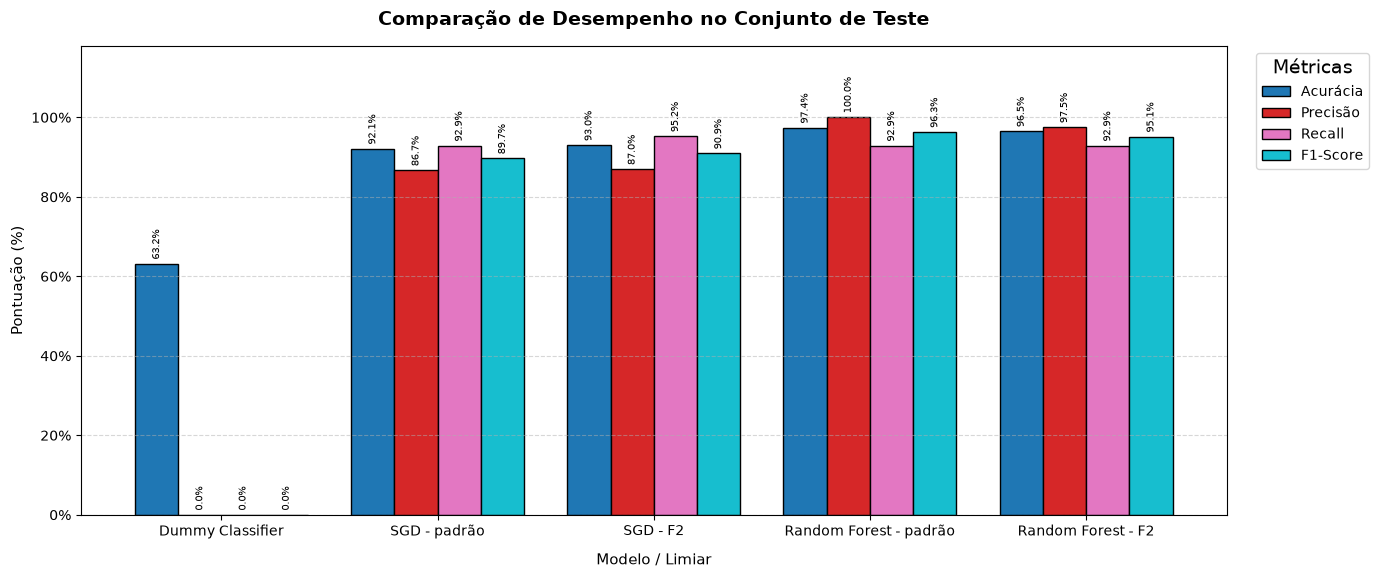

In [53]:
# Configurações do Gráfico (as 4 métricas pedidas no enunciado)
fig, ax = plt.subplots(figsize=(14, 6))

df_teste[['Acurácia', 'Precisão', 'Recall', 'F1-Score']].plot(
    kind="bar", ax=ax, width=0.8, colormap="tab10", edgecolor="black"
)

# Estilização
plt.title("Comparação de Desempenho no Conjunto de Teste", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Modelo / Limiar", fontsize=11, labelpad=10)
plt.ylabel("Pontuação (%)", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.ylim(0, 1.18)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Formata o eixo Y em Porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# Adiciona o valor exato em cima de cada barra
for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=7, rotation=90)

plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

**Observações:**

* **Dummy:** acurácia de 63,16% (a proporção de benignos no teste) e **42 falsos negativos**: nenhum dos 42 tumores malignos é detectado.
* **SGD:** no limiar padrão, 3 FN e 6 FP. Com o limiar F2, os FN caíram para **2** (recall de 92,86% para **95,24%**), **sem aumento de falsos positivos** (continuaram 6).
* **Random Forest:** no limiar padrão, 3 FN e **nenhum** FP (precisão de 100%). Com o limiar F2, os FN continuaram 3 (recall de 92,86%) e surgiu 1 FP: no teste, o ajuste do limiar não trouxe ganho de recall para este modelo.
* Maior recall no teste: **SGD com limiar F2** (40 de 42 malignos detectados). Maior acurácia e precisão: **Random Forest no limiar padrão** (97,37% e 100%).
* As diferenças de recall entre os modelos no teste são de **1 tumor** (2 contra 3 FN), e cada maligno vale cerca de 2,4 pontos percentuais. Com um teste de 114 amostras, essas diferenças não permitem afirmar que um modelo é superior.
* Estes resultados são definitivos para o exercício: nenhum modelo, parâmetro ou limiar foi alterado depois desta avaliação.

# **6. Comparação Final e Conclusão**

A tabela abaixo coloca lado a lado, para cada modelo e limiar:

* **Treino (validação cruzada):** previsões fora da amostra das seções 4.1 a 4.2 (455 tumores, 170 malignos);
* **Teste:** avaliação final da seção 5 (114 tumores, 42 malignos).

Nas duas colunas, cada tumor foi classificado por um modelo que não o viu no treinamento.

In [54]:
# Previsões de cada modelo e limiar: (treino fora da amostra, teste)
previsoes_finais = {
    'Dummy': (y_train_pred_dummy, y_pred_dummy),
    'SGD - padrão': (y_train_pred_sgd, y_pred_sgd),
    'SGD - F2': (y_train_pred_sgd_f2, y_pred_sgd_f2),
    'Random Forest - padrão': (y_train_pred_forest, y_pred_forest),
    'Random Forest - F2': (y_train_pred_forest_f2, y_pred_forest_f2),
}

linhas = []
for modelo, (pred_treino, pred_teste) in previsoes_finais.items():
    for conjunto, y_real, y_pred in [('Treino (validação cruzada)', y_train, pred_treino),
                                     ('Teste', y_test, pred_teste)]:
        linhas.append({
            'Modelo': modelo,
            'Conjunto': conjunto,
            'Recall': recall_score(y_real, y_pred),
            'Precisão': precision_score(y_real, y_pred, zero_division=0),
            'F1-Score': f1_score(y_real, y_pred, zero_division=0),
            'Acurácia': accuracy_score(y_real, y_pred),
            'FN': ((y_real == 1) & (y_pred == 0)).sum(),
            'FP': ((y_real == 0) & (y_pred == 1)).sum(),
            'Malignos': (y_real == 1).sum(),
        })

df_final = pd.DataFrame(linhas).set_index(['Modelo', 'Conjunto'])

colunas_pct = ['Recall', 'Precisão', 'F1-Score', 'Acurácia']
df_final[colunas_pct].map('{:.2%}'.format).join(df_final[['FN', 'FP', 'Malignos']])

Recall Precisão F1-Score  \
Modelo                 Conjunto                                               
Dummy                  Treino (validação cruzada)   0.00%    0.00%    0.00%   
                       Teste                        0.00%    0.00%    0.00%   
SGD - padrão           Treino (validação cruzada)  95.88%   95.88%   95.88%   
                       Teste                       92.86%   86.67%   89.66%   
SGD - F2               Treino (validação cruzada)  97.65%   92.74%   95.13%   
                       Teste                       95.24%   86.96%   90.91%   
Random Forest - padrão Treino (validação cruzada)  94.71%   94.15%   94.43%   
                       Teste                       92.86%  100.00%   96.30%   
Random Forest - F2     Treino (validação cruzada)  96.47%   92.66%   94.52%   
                       Teste                       92.86%   97.50%   95.12%   

                                                  Acurácia   FN  FP  Malignos  
Modelo                 Conjunto                                                
Dummy                  Treino (validação cruzada)   62.64%  170   0       170  
                       Teste                        63.16%   42   0        42  
SGD - padrão           Treino (validação cruzada)   96.92%    7   7       170  
                       Teste                        92.11%    3   6        42  
SGD - F2               Treino (validação cruzada)   96.26%    4  13       170  
                       Teste                        92.98%    2   6        42  
Random Forest - padrão Treino (validação cruzada)   95.82%    9  10       170  
                       Teste                        97.37%    3   0        42  
Random Forest - F2     Treino (validação cruzada)   95.82%    6  13       170  
                       Teste                        96.49%    3   1        42

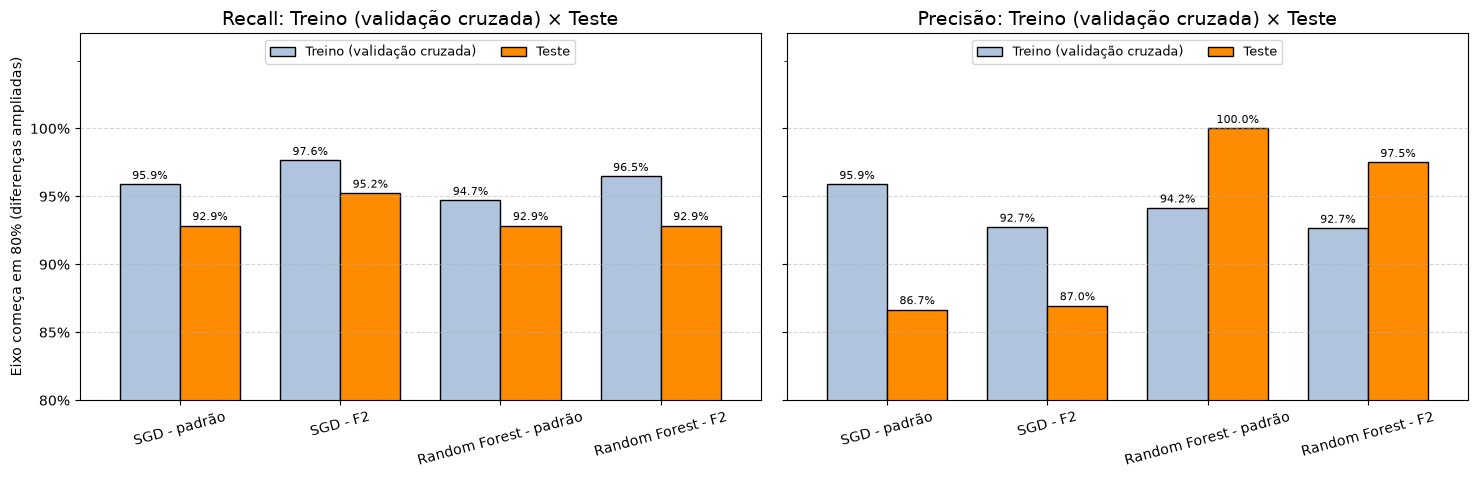

In [55]:
# Recall e Precisão no treino (validação cruzada) e no teste, para os modelos reais
modelos_reais = ['SGD - padrão', 'SGD - F2', 'Random Forest - padrão', 'Random Forest - F2']

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, metrica in zip(axes, ['Recall', 'Precisão']):
    tabela = df_final[metrica].unstack('Conjunto').loc[modelos_reais,
                                                       ['Treino (validação cruzada)', 'Teste']]
    tabela.plot(kind='bar', ax=ax, width=0.75, color=['lightsteelblue', 'darkorange'], edgecolor='black')
    ax.set_title(f"{metrica}: Treino (validação cruzada) × Teste")
    ax.set_xlabel("")
    ax.set_ylim(0.8, 1.07)
    ax.set_yticks(np.arange(0.80, 1.001, 0.05))
    ax.set_ylabel("Eixo começa em 80% (diferenças ampliadas)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(loc='upper center', ncol=2, fontsize=9)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v * 100:.1f}%" for v in container.datavalues],
                     padding=2, fontsize=8)

plt.tight_layout()
plt.show()

## **6.1. Interpretação dos Resultados**

1. **Linha de base.** O Dummy obteve cerca de 63% de acurácia no treino e no teste sem detectar nenhum tumor maligno (recall 0%: 170 e 42 falsos negativos). Isso confirma que a **acurácia sozinha é enganosa** neste problema.

2. **Os modelos reais aprenderam.** SGD e Random Forest detectaram entre **39 e 40 dos 42 malignos do teste** (recall de 92,86% a 95,24%), muito acima do Dummy.

3. **Recall: treino × teste.** Em todas as variantes, o recall no teste foi um pouco menor que o estimado no treino (de 1,9 a 3,6 pontos percentuais). Como cada maligno do teste vale cerca de 2,4 pontos, as diferenças equivalem a 1 ou 2 tumores.

4. **Precisão: treino × teste.** Aqui os modelos divergiram. O SGD gerou **6 falsos positivos** em 72 benignos do teste (precisão ≈ 87%, contra ≈ 93–96% no treino). A Random Forest gerou **0 ou 1** (precisão de 97,5% a 100%). Com um único conjunto de teste pequeno, não é possível determinar se essa diferença é variação amostral ou uma diferença real de generalização.

5. **Ajuste do limiar (F2).** No treino, baixar o limiar detectou 3 malignos a mais nos dois modelos, com 3 (RF) a 6 (SGD) falsos positivos adicionais. No teste, o efeito foi menor e diferente entre os modelos: o SGD detectou **1 maligno a mais sem nenhum falso positivo adicional**, enquanto na Random Forest o recall **não mudou** e surgiu 1 falso positivo. Ajustar o limiar desloca o equilíbrio entre FN e FP, mas o ganho em dados novos depende de onde caem as pontuações desses dados.

6. **Qual configuração escolher?**
    * Com a **prioridade do exercício (recall)**, o **SGD com limiar F2** teve o maior recall tanto no treino (97,65%) quanto no teste (95,24%; 2 falsos negativos).
    * A **Random Forest no limiar padrão** teve a maior acurácia (97,37%), precisão (100%) e F1 (96,30%) no teste, com 3 falsos negativos e nenhum falso positivo.
    * A diferença de recall entre essas configurações no teste é de **1 tumor**. Os dados não permitem afirmar que uma é superior; a escolha depende do custo atribuído a um falso negativo em relação a um falso positivo.

## **6.2. Conclusão**

O exercício classificou tumores de mama em **Maligno (1)** e **Benigno (0)** com os três modelos da atividade de referência. Depois de confirmar e corrigir a codificação do alvo, separar um conjunto de teste estratificado e evitar vazamento com `Pipeline`, os modelos foram comparados por validação cruzada no treino e avaliados uma única vez no teste.

* SGD e Random Forest superaram amplamente a linha de base, com recall acima de 92% no teste, enquanto o Dummy não detectou nenhum câncer.
* O **ajuste do limiar orientado a recall**, escolhido apenas com o treino, mostrou o *trade-off* entre falsos negativos e falsos positivos. No teste, trouxe ganho de 1 tumor detectado no SGD e nenhum ganho na Random Forest.
* A configuração mais alinhada à prioridade do exercício foi o **SGD com limiar F2** (maior recall no treino e no teste), e a de menor número de falsos positivos foi a **Random Forest no limiar padrão**. As diferenças observadas são de poucos tumores e não estabelecem superioridade de um modelo.

**Limitações:** dataset pequeno (569 tumores; 42 malignos no teste), um único conjunto de teste, hiperparâmetros padrão (sem ajuste) e dados de uma única origem (Wisconsin, 1995).

**Estes resultados são de um exercício acadêmico e não têm validade para uso clínico.**